# Batch-convert HDF5 4D-STEM datasets to the 198.zip (Zarr) format

This is the batch version of `h5_to_ptycho_zarr.ipynb`. It runs the same conversion on every folder in a list.
Each folder holds one HDF5 file, which becomes one `.zip` in the same zipped **Zarr** layout as `198.zip`:

| Entry | Contents |
|---|---|
| `.zgroup` | Zarr group header |
| `data/` | 16-bit integer counts, shape `(scan_y, scan_x, det_y, det_x)`, chunks `(66, 66, det_y, det_x)` (smaller automatically for large detectors), Blosc lz4 compression |
| `meta/` | one JSON record: `E_ev`, `aberrations` (12), `alpha_rad`, `k_max`, `pixel_step`, `rotation_deg`, `sample_thickness_guess_angstrom`, `scan_step`, `wavelength` |

**How to use it:** edit the cells marked ✏️, then run the notebook from the top.

1. List the folders and choose where the outputs go.
2. Fill in the microscope settings. Settings that differ for particular scans go in `OVERRIDES`.
3. Check that every folder's file is found and readable, and check the calibration on one scan *before* converting.
4. Convert all the scans. Finished files are skipped, so you can stop the run and start it again safely.
5. Look at the summary: a table, plus a virtual bright-field image for every scan.
6. Optional: compare one converted file with a reference.

For every scan, Step 4 also saves a check image (mean pattern, virtual bright field, total counts) and adds a
row to `conversion_log.csv`.

Requirements: `pip install h5py hdf5plugin numpy matplotlib "zarr<3" numcodecs`

In [1]:
import os, glob, time, shutil, csv, json
from types import SimpleNamespace
from urllib.parse import unquote
import numpy as np
import h5py
try:
    import hdf5plugin  # registers extra HDF5 compression filters; must be imported before reading data
    print("hdf5plugin", hdf5plugin.version, "loaded")
except ImportError:
    print("WARNING: hdf5plugin is not installed. If your data are compressed, run\n"
          "    pip install hdf5plugin\nthen restart the kernel and run the notebook again.")
import zarr
import numcodecs
from numcodecs import Blosc
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

print("zarr", zarr.__version__, "| numcodecs", numcodecs.__version__, "| h5py", h5py.__version__)
assert int(zarr.__version__.split(".")[0]) == 2, "This notebook needs zarr version 2:  pip install 'zarr<3'"

hdf5plugin 4.1.3 loaded
zarr 2.18.3 | numcodecs 0.12.1 | h5py 3.16.0


## Step 1 — Folders and outputs ✏️

Paste the folders into `FOLDERS_TEXT`, one per line. Lines copied from the Files app (`file:///dls/...`) work
as they are, and other lines (such as the `x-special/nautilus-clipboard` and `copy` header) are ignored.

In each folder the notebook converts `<folder name>_data.hdf5`. If that file isn't there, it uses the folder's
only `.hdf5` or `.h5` file. Folders with no HDF5 file, or with several, are reported in Step 3 and skipped.

* **`OUTPUT_DIR`**: where the `.zip` files go. Each one is named after its folder (`20260524_112119.zip`), and
  the check images go in a `checks` subfolder. Set it to `None` to write each `.zip` into its own data folder instead.
* **`OVERWRITE`**: `False` skips scans whose `.zip` already exists, so a stopped run carries on where it left off.
  `True` converts everything again.

In [3]:
FOLDERS_TEXT = """
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_112119
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_112644
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_113110
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_113554
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_114023
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_114443
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_114951
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_115357
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_120002
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_120714
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_121253
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_123150
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_123848
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_124500
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_125048
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_125551
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_130110
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_130621
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_131438
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_132150
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_132837
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_142013
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_142713
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_143822
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_144451
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_144945
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_145429
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_145912
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_150646
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_151201
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_152057
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_152815
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_153450
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_154302
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_154911
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_155607
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_160023
/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_160606
"""

OUTPUT_DIR = "/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/Zarr"   # None = next to each HDF5 file
OVERWRITE = False         # False = skip scans that already have a .zip

## Step 2 — Microscope settings ✏️

The values below are copied from the single-file notebook. Every scan uses them, except where `OVERRIDES` says otherwise.
They are written into every output file, so check them in Step 3 before converting.

* **`DATASET`**: path of the diffraction data inside the HDF5 file.
  Leave as `None` to pick it automatically when there is exactly one 4D dataset.
* **`SCAN_SHAPE`**: only needed if the patterns are stored as a flat stack `(n_patterns, det_y, det_x)`;
  then give the scan grid, e.g. `(220, 220)`. The data are assumed to be ordered
  `(scan_y, scan_x, det_y, det_x)`.
* **Detector calibration**: fill in **exactly one** of `K_MAX`, `DK` or `MRAD_PER_PX` and leave the
  other two as `None`.
* **`DEFOCUS_A`**: probe defocus in Å, stored as the first aberration coefficient (198.zip uses −252).
  Use `ABERRATIONS` instead if you have all 12 coefficients.
* **`BIN`**: optional detector binning. `1` keeps every pixel; `2`, `4`, `8`… add up `BIN × BIN` blocks of
  pixels, making the patterns (and the file) smaller. Give the detector calibration for the *unbinned*
  detector; the notebook adjusts it. 198.zip has 66 × 66-pixel patterns at 0.038 Å⁻¹ per pixel.
* **`CHUNK`**: leave as `None`. It then uses 66 × 66 scan positions per block like 198.zip, or fewer
  when the patterns are large (the compressor can't handle blocks over 2 GB).
* **`OVERRIDES`**: settings that differ for particular scans, keyed by folder name. Use any name from this cell, for example
  for a focal series:
  `{"20260524_112119": {"DEFOCUS_A": -200.0}, "20260524_112644": {"DEFOCUS_A": -150.0}}`.
  A new `DEFOCUS_A` replaces only the first coefficient when `ABERRATIONS` is set, and a new calibration
  (`K_MAX`, `DK` or `MRAD_PER_PX`) replaces the one above. Leave it as `{}` when all scans share the same settings.

In [4]:
DATASET = None            # e.g. "/entry/data"; None = find the 4D dataset automatically
SCAN_SHAPE = None         # e.g. (220, 220), only for a flat (n_patterns, det_y, det_x) stack

VOLTAGE_KV = 300.0         # accelerating voltage, kV
ALPHA_MRAD = 26.7         # probe convergence semi-angle, mrad
SCAN_STEP_A = (0.78125, 0.78125)   # scan step (y, x), Å

# Detector calibration: fill in exactly ONE of these three, leave the others as None
K_MAX = None                  # half-width of the detector, 1/Å (as stored in meta.k_max)
DK = None                     # size of one detector pixel, 1/Å
MRAD_PER_PX = 0.055 / 170 * 1e3   # size of one detector pixel, mrad: 55 µm pixels at 170 mm camera length (= 0.3235)

DEFOCUS_A = 200.0        # defocus C1, Å
ABERRATIONS = None        # or a list of all 12 coefficients (overrides DEFOCUS_A)
ROTATION_DEG = -85.5        # scan-to-detector rotation, degrees
THICKNESS_A = 300         # sample thickness guess, Å

BIN = 1                   # detector binning: 1 = none; 2, 4, 8 ... = sum BIN x BIN pixels
CHUNK = None              # scan positions per block; None = automatic (66 like 198.zip, fewer for big patterns)

# Settings that differ for particular scans, keyed by folder name; {} = all scans use the values above
OVERRIDES = {
    # "20260524_112119": {"DEFOCUS_A": -200.0},
}

The next cell holds the conversion: the same steps as the single-file notebook, wrapped in functions so that
they can run once per scan. The data written are identical. One thing changed: when the notebook measures the
bright-field disk, it now ignores isolated hot pixels. In the single-file run, one bright pixel set the threshold
(measured radius 0.6 px), which spoiled the calibration check and the virtual bright-field image.

Running this cell defines the functions only. Nothing is read or written yet.

In [5]:
# ---------- folders and files ----------

def parse_folders(text):
    # Folder paths from pasted text: plain paths or file:// lines from the Files app; other lines are ignored
    folders = []
    for line in text.splitlines():
        line = line.strip()
        if line.startswith("file://"):
            line = unquote(line[len("file://"):])
        line = line.rstrip("/")
        if line.startswith("/") and line not in folders:
            folders.append(line)
    return folders


def find_h5(folder):
    # The file to convert in one folder: <folder name>_data.hdf5, or else the folder's only .hdf5/.h5 file
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"folder not found: {folder}")
    preferred = os.path.join(folder, os.path.basename(folder) + "_data.hdf5")
    if os.path.isfile(preferred):
        return preferred
    found = sorted(f for f in glob.glob(os.path.join(folder, "*"))
                   if f.lower().endswith((".hdf5", ".h5")) and os.path.isfile(f))
    if len(found) == 1:
        return found[0]
    if not found:
        raise FileNotFoundError(f"no .hdf5 or .h5 file in {folder}")
    raise ValueError(f"{len(found)} HDF5 files, can't tell which to convert: "
                     + ", ".join(os.path.basename(f) for f in found))


def output_paths(folder):
    # (.zip path, path prefix for the check image and check data) of one scan
    name = os.path.basename(folder)
    if OUTPUT_DIR:
        return os.path.join(OUTPUT_DIR, name + ".zip"), os.path.join(OUTPUT_DIR, "checks", name)
    return os.path.join(folder, name + ".zip"), os.path.join(folder, name + "_check")


# ---------- Step 2 settings for one scan ----------

CAL_NAMES = ("K_MAX", "DK", "MRAD_PER_PX")
SETTING_NAMES = ("DATASET", "SCAN_SHAPE", "VOLTAGE_KV", "ALPHA_MRAD", "SCAN_STEP_A") + CAL_NAMES + (
    "DEFOCUS_A", "ABERRATIONS", "ROTATION_DEG", "THICKNESS_A", "BIN", "CHUNK")


def settings_for(name):
    # The Step 2 settings for one scan, with its OVERRIDES applied
    s = {k: globals()[k] for k in SETTING_NAMES}
    extra = dict(OVERRIDES.get(name, {}))
    unknown = set(extra) - set(SETTING_NAMES)
    if unknown:
        raise ValueError(f"OVERRIDES[{name!r}] has unknown setting(s) {sorted(unknown)}; use names from Step 2")
    if any(k in extra for k in CAL_NAMES):          # a new calibration replaces the default one
        s.update({k: None for k in CAL_NAMES})
    if "DEFOCUS_A" in extra and "ABERRATIONS" not in extra and s["ABERRATIONS"] is not None:
        s["ABERRATIONS"] = [extra["DEFOCUS_A"]] + list(s["ABERRATIONS"][1:])
    s.update(extra)
    return s


# ---------- from the single-file notebook ----------

def electron_wavelength_angstrom(voltage_v):
    # Relativistic electron wavelength in Å
    h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
    p = np.sqrt(2 * m0 * e * voltage_v * (1 + e * voltage_v / (2 * m0 * c**2)))
    return h / p * 1e10


def as_pair(v):
    return [float(v), float(v)] if np.isscalar(v) else [float(x) for x in v]


def filter_names(dset):
    # Names of the HDF5 filters (compression etc.) applied to a dataset
    plist = dset.id.get_create_plist()
    names = []
    for i in range(plist.get_nfilters()):
        code, _, _, name = plist.get_filter(i)
        name = name.decode(errors="replace") if isinstance(name, bytes) else str(name)
        names.append(f"{name} (id {code})")
    return names


def list_h5(path):
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            filt = ", ".join(filter_names(obj)) or "none"
            print(f"[dataset] /{name}   shape={obj.shape}   dtype={obj.dtype}   compression: {filt}")
        else:
            print(f"[group]   /{name}")
        for k, v in obj.attrs.items():
            s = repr(v)
            print(f"             @{k} = {s[:120]}{'...' if len(s) > 120 else ''}")

    with h5py.File(path, "r") as f:
        for k, v in f.attrs.items():
            print(f"[file attribute] @{k} = {repr(v)[:120]}")
        f.visititems(show)


def find_dataset(f, dataset=None, scan_shape=None):
    if dataset:
        return f[dataset]
    found = []
    f.visititems(lambda n, o: found.append(o.name) if isinstance(o, h5py.Dataset)
                 and (o.ndim == 4 or (o.ndim == 3 and scan_shape)) else None)
    if len(found) != 1:
        raise ValueError(f"Found {len(found)} candidate datasets {found}; set DATASET in Step 2.")
    return f[found[0]]


def prepare(input_h5, s):
    # What the Step 2 cell of the single-file notebook works out (shapes, calibration, metadata), for one scan
    with h5py.File(input_h5, "r") as f:
        src = find_dataset(f, s["DATASET"], s["SCAN_SHAPE"])
        dataset_path, src_shape, src_dtype = src.name, src.shape, src.dtype
        src_filters = filter_names(src)
        # test-read one pattern so a missing decompression filter shows up here, with a clear message
        try:
            src[(0,) * (src.ndim - 2)]
        except OSError as err:
            raise RuntimeError(
                f"Can't decompress {dataset_path} (filters: {', '.join(src_filters) or 'none'}). "
                "Install the extra HDF5 filters with   pip install hdf5plugin   then restart the kernel "
                f"and run the notebook from the top. Original error: {err}") from None

    if len(src_shape) == 4:
        Ry, Rx, Qy_raw, Qx_raw = src_shape
    elif len(src_shape) == 3 and s["SCAN_SHAPE"]:
        Ry, Rx = s["SCAN_SHAPE"]
        Qy_raw, Qx_raw = src_shape[1:]
        assert src_shape[0] == Ry * Rx, f"SCAN_SHAPE gives {Ry*Rx} patterns but the dataset has {src_shape[0]}"
    else:
        raise ValueError(f"Dataset shape {src_shape}: expected 4D, or 3D with SCAN_SHAPE set.")

    assert sum(s[k] is not None for k in CAL_NAMES) == 1, "Set exactly one of K_MAX, DK, MRAD_PER_PX"
    BIN = s["BIN"]
    assert isinstance(BIN, int) and BIN >= 1, "BIN must be a whole number >= 1"

    lam = electron_wavelength_angstrom(s["VOLTAGE_KV"] * 1e3)
    # calibration of the raw (unbinned) detector pixels
    if s["K_MAX"] is not None:
        k_raw = as_pair(s["K_MAX"])
        dk_raw = [2 * k_raw[0] / Qy_raw, 2 * k_raw[1] / Qx_raw]
    else:
        dk_raw = as_pair(s["DK"]) if s["DK"] is not None else [m * 1e-3 / lam for m in as_pair(s["MRAD_PER_PX"])]

    # optional binning: leftover edge pixels (if the size isn't a multiple of BIN) are cropped evenly
    Qy, Qx = Qy_raw // BIN, Qx_raw // BIN
    crop_y, crop_x = (Qy_raw - Qy * BIN) // 2, (Qx_raw - Qx * BIN) // 2
    dk = [d * BIN for d in dk_raw]
    k_max = [Qy * dk[0] / 2, Qx * dk[1] / 2]

    # block (chunk) size: the Blosc compressor can't take blocks over 2 GB, so keep them under 1 GB
    bytes_per_pattern = Qy * Qx * 2
    if s["CHUNK"] is None:
        chunk = 66 if 66 * 66 * bytes_per_pattern <= 2**30 else max(1, int(np.sqrt(2**30 / bytes_per_pattern)))
    else:
        chunk = int(s["CHUNK"])
    assert chunk**2 * bytes_per_pattern < 2**31, f"CHUNK={chunk} makes blocks over 2 GB; set CHUNK = None"

    ab = s["ABERRATIONS"]
    aberrations = [float(a) for a in ab] if ab is not None else [float(s["DEFOCUS_A"])] + [0.0] * 11
    assert len(aberrations) == 12, "ABERRATIONS needs 12 values"

    meta = {
        "E_ev": s["VOLTAGE_KV"] * 1e3,
        "aberrations": aberrations,
        "alpha_rad": s["ALPHA_MRAD"] * 1e-3,
        "k_max": k_max,
        "pixel_step": [1.0, 1.0],
        "rotation_deg": float(s["ROTATION_DEG"]),
        "sample_thickness_guess_angstrom": float(s["THICKNESS_A"]),
        "scan_step": as_pair(s["SCAN_STEP_A"]),
        "wavelength": float(lam),
    }
    return SimpleNamespace(
        h5=input_h5, dataset_path=dataset_path, src_shape=src_shape, src_dtype=src_dtype, src_filters=src_filters,
        Ry=Ry, Rx=Rx, Qy_raw=Qy_raw, Qx_raw=Qx_raw, Qy=Qy, Qx=Qx, crop_y=crop_y, crop_x=crop_x, bin=BIN,
        lam=lam, dk=dk, k_max=k_max, chunk=chunk, bytes_per_pattern=bytes_per_pattern, meta=meta,
        expected_radius_px=s["ALPHA_MRAD"] * 1e-3 / lam / np.sqrt(dk[0] * dk[1]))


def describe(p):
    # The printout of the Step 2 cell of the single-file notebook
    print(f"Dataset {p.dataset_path}: shape {p.src_shape}, dtype {p.src_dtype}, "
          f"compression: {', '.join(p.src_filters) or 'none'}")
    if p.bin > 1:
        print(f"Binning {p.bin}x{p.bin}: detector {p.Qy_raw}x{p.Qx_raw} -> {p.Qy}x{p.Qx} pixels")
    print(f"Output shape (scan_y, scan_x, det_y, det_x) = {(p.Ry, p.Rx, p.Qy, p.Qx)}")
    print(f"Blocks of {p.chunk}x{p.chunk} scan positions = {p.chunk**2 * p.bytes_per_pattern / 1e9:.2f} GB each "
          f"(uncompressed); whole dataset {p.Ry * p.Rx * p.bytes_per_pattern / 1e9:.1f} GB uncompressed")
    print(f"Field of view: {p.Ry * p.meta['scan_step'][0] / 10:.2f} x {p.Rx * p.meta['scan_step'][1] / 10:.2f} nm")
    print(f"Detector: {p.dk[0]:.4f} 1/Å per pixel = {p.dk[0] * p.lam * 1e3:.3f} mrad per pixel")
    print(f"Expected bright-field disk radius: {p.expected_radius_px:.1f} pixels")
    if p.expected_radius_px > min(p.Qy, p.Qx) / 2:
        print("WARNING: that disk is bigger than the detector - check VOLTAGE_KV, ALPHA_MRAD and the detector calibration.")
    print("\nMetadata record to be written:")
    print(json.dumps(p.meta, indent=2))


def bin_patterns(a, p):
    # Crop leftover edge pixels and add up BIN x BIN blocks of detector pixels
    if p.bin == 1:
        return a
    a = a[..., p.crop_y:p.crop_y + p.Qy * p.bin, p.crop_x:p.crop_x + p.Qx * p.bin]
    return a.reshape(a.shape[:-2] + (p.Qy, p.bin, p.Qx, p.bin)).sum(axis=(-3, -1))


def read_block(src, p, r0, r1, c0, c1):
    # Return (binned) patterns for scan rows r0:r1, columns c0:c1 as an array (r, c, det_y, det_x).
    # With binning, one scan row is read and binned at a time to keep memory use low.
    if src.ndim == 4:
        if p.bin == 1:
            return np.asarray(src[r0:r1, c0:c1])
        return np.stack([bin_patterns(np.asarray(src[r, c0:c1]), p) for r in range(r0, r1)])
    return np.stack([bin_patterns(np.asarray(src[r * p.Rx + c0:r * p.Rx + c1]), p) for r in range(r0, r1)])


# ---------- calibration check (Step 3 of the single-file notebook) ----------

def suppress_hot_pixels(img, size=5):
    # 5x5 median filter: removes isolated hot or dead pixels but keeps the edge of the bright-field disk
    h = size // 2
    a = np.pad(img, h, mode="edge")
    return np.median([a[i:i + img.shape[0], j:j + img.shape[1]] for i in range(size) for j in range(size)], axis=0)


def disk_from_mean(mean_dp):
    smooth = suppress_hot_pixels(mean_dp)
    mask = smooth > 0.5 * smooth.max()
    yy, xx = np.nonzero(mask)
    return yy.mean(), xx.mean(), np.sqrt(mask.sum() / np.pi)


def check_calibration(p):
    # Average a sparse grid of ~1000 patterns and measure the bright-field disk
    step = max(1, int(np.sqrt(p.Ry * p.Rx / 1000)))
    acc, n = np.zeros((p.Qy, p.Qx)), 0
    with h5py.File(p.h5, "r") as f:
        src = f[p.dataset_path]
        for r in range(0, p.Ry, step):
            for c in range(0, p.Rx, step):
                acc += read_block(src, p, r, r + 1, c, c + 1)[0, 0]
                n += 1
    mean = acc / n
    cy, cx, r = disk_from_mean(mean)
    ok = abs(r - p.expected_radius_px) <= 0.1 * p.expected_radius_px
    return SimpleNamespace(mean=mean, n=n, cy=cy, cx=cx, r=r, ok=ok)


def draw_pattern(ax, img, p, cal, title):
    # A diffraction pattern in 1/Å, with the expected (dashed) and measured (solid) bright-field disk
    ext = [-p.k_max[1], p.k_max[1], p.k_max[0], -p.k_max[0]]
    ky0, kx0 = (cal.cy - (p.Qy - 1) / 2) * p.dk[0], (cal.cx - (p.Qx - 1) / 2) * p.dk[1]
    px = np.sqrt(p.dk[0] * p.dk[1])
    ax.imshow(img, extent=ext, cmap="magma", vmax=suppress_hot_pixels(img).max())   # hot pixels don't set the scale
    ax.add_patch(Circle((kx0, ky0), p.expected_radius_px * px, fill=False, ls="--", lw=1.5, color="cyan",
                        label="expected"))
    ax.add_patch(Circle((kx0, ky0), cal.r * px, fill=False, lw=1, color="white", alpha=0.7, label="measured"))
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    ax.set_title(title); ax.set_xlabel("kx (1/Å)"); ax.set_ylabel("ky (1/Å)")
    ax.legend(loc="upper right", fontsize=8)


def report_calibration(p, cal):
    print(f"Bright-field disk: measured radius {cal.r:.1f} px, expected {p.expected_radius_px:.1f} px")
    print(f"Disk centre at detector pixel ({cal.cy:.1f}, {cal.cx:.1f}); detector centre is "
          f"({(p.Qy - 1) / 2:.1f}, {(p.Qx - 1) / 2:.1f})")
    if cal.ok:
        print("OK: calibration and convergence angle are consistent.")
    else:
        print("WARNING: these differ by more than 10% - check ALPHA_MRAD and the detector calibration.")


# ---------- conversion and verification (Steps 4 and 5 of the single-file notebook) ----------

def convert(p, cal, out_path):
    # Write one scan block by block; also builds the virtual bright-field image, total counts and mean pattern
    yy, xx = np.mgrid[:p.Qy, :p.Qx]
    bf_mask = np.hypot(yy - cal.cy, xx - cal.cx) <= 0.9 * cal.r

    store = zarr.ZipStore(out_path, mode="w")
    try:
        root = zarr.group(store=store, overwrite=True)
        out = root.create_dataset(
            "data", shape=(p.Ry, p.Rx, p.Qy, p.Qx), chunks=(min(p.chunk, p.Ry), min(p.chunk, p.Rx), p.Qy, p.Qx),
            dtype="<i2", fill_value=0, order="C",
            compressor=Blosc(cname="lz4", clevel=1, shuffle=Blosc.SHUFFLE))

        n_rounded, vmin, vmax = 0, np.inf, -np.inf
        total = np.zeros((p.Ry, p.Rx))
        vbf = np.zeros((p.Ry, p.Rx))
        mean_dp = np.zeros((p.Qy, p.Qx))
        with h5py.File(p.h5, "r") as f:
            src = f[p.dataset_path]
            for r0 in range(0, p.Ry, p.chunk):
                r1 = min(r0 + p.chunk, p.Ry)
                for c0 in range(0, p.Rx, p.chunk):
                    c1 = min(c0 + p.chunk, p.Rx)
                    blk = read_block(src, p, r0, r1, c0, c1)
                    if not np.issubdtype(blk.dtype, np.integer):
                        rounded = np.rint(blk)
                        n_rounded += int(np.count_nonzero(np.abs(blk - rounded) > 1e-6))
                        blk = rounded
                    if blk.min() < -32768 or blk.max() > 32767:
                        raise ValueError(f"Values {blk.min()}..{blk.max()} don't fit in int16; "
                                         "rescale the data to electron counts first.")
                    vmin, vmax = min(vmin, blk.min()), max(vmax, blk.max())
                    blk = blk.astype("<i2")
                    out[r0:r1, c0:c1] = blk
                    total[r0:r1, c0:c1] = blk.sum(axis=(2, 3))
                    vbf[r0:r1, c0:c1] = blk[..., bf_mask].sum(axis=-1)
                    mean_dp += blk.sum(axis=(0, 1))
                    del blk
                print(".", end="", flush=True)

        m = root.create_dataset("meta", shape=(1,), chunks=(1,), dtype=object,
                                object_codec=numcodecs.JSON(),
                                compressor=Blosc(cname="lz4", clevel=5, shuffle=Blosc.SHUFFLE))
        m[0] = p.meta
    finally:
        store.close()

    mean_dp /= p.Ry * p.Rx
    return SimpleNamespace(vmin=vmin, vmax=vmax, n_rounded=n_rounded, total=total, vbf=vbf, mean_dp=mean_dp)


def verify(p, out_path, n_check=20):
    # Re-open the .zip: check shape, type and metadata, and compare random patterns with the HDF5 source.
    # Returns a list of problems (empty = all good).
    problems = []
    store = zarr.ZipStore(out_path, mode="r")
    try:
        g = zarr.open_group(store, mode="r")
        a = g["data"]
        if a.shape != (p.Ry, p.Rx, p.Qy, p.Qx) or a.dtype != np.dtype("<i2"):
            problems.append(f"data is {a.shape} {a.dtype}")
        if g["meta"][0] != p.meta:
            problems.append("metadata record differs from the settings")
        rng = np.random.default_rng(0)
        same = True
        with h5py.File(p.h5, "r") as f:
            src = f[p.dataset_path]
            for _ in range(n_check):
                r, c = int(rng.integers(p.Ry)), int(rng.integers(p.Rx))
                orig = np.rint(read_block(src, p, r, r + 1, c, c + 1)[0, 0])
                same &= np.array_equal(orig, a[r, c])
        if not same:
            problems.append(f"some of {n_check} random patterns differ from the HDF5 source")
    finally:
        store.close()
    return problems


def save_check(job, p, cal, stats):
    # Check image (mean pattern with disk, virtual bright field, total counts) and its data, for one scan
    base = job["check"]
    os.makedirs(os.path.dirname(base), exist_ok=True)
    np.savez(base + ".npz", mean_dp=stats.mean_dp, vbf=stats.vbf, total=stats.total,
             disk_cy_cx_r=[cal.cy, cal.cx, cal.r], expected_radius_px=p.expected_radius_px)
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    draw_pattern(ax[0], np.log10(stats.mean_dp + 1e-3), p, cal, "Mean diffraction pattern (log)")
    ext_r = [0, p.Rx * p.meta["scan_step"][1] / 10, p.Ry * p.meta["scan_step"][0] / 10, 0]
    ax[1].imshow(stats.vbf, extent=ext_r, cmap="gray"); ax[1].set_title("Virtual bright field")
    ax[2].imshow(stats.total, extent=ext_r, cmap="gray"); ax[2].set_title("Total counts per pattern")
    for a in ax[1:]:
        a.set_xlabel("x (nm)"); a.set_ylabel("y (nm)")
    fig.suptitle(f"{job['name']}   |   bright-field disk {cal.r:.1f} px measured, "
                 f"{p.expected_radius_px:.1f} px expected{'' if cal.ok else '  (CHECK)'}")
    fig.tight_layout()
    fig.savefig(base + ".png", dpi=80)
    plt.close(fig)


LOG_FIELDS = ["finished", "name", "status", "input", "output", "shape", "size_GB", "minutes",
              "value_range", "mean_counts", "disk_measured_px", "disk_expected_px", "error"]


def log_row(path, row):
    new = not os.path.exists(path)
    with open(path, "a", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=LOG_FIELDS, extrasaction="ignore")
        if new:
            w.writeheader()
        w.writerow(row)


def fmt_time(seconds):
    m = int(round(seconds / 60))
    return f"{m // 60}h{m % 60:02d}m" if m >= 60 else f"{max(seconds, 1) / 60:.1f} min"


print("Functions defined.")

Functions defined.


## Step 3 — Check the files and the calibration before converting

The first cell finds the HDF5 file in each folder, reads its shape and test-reads one pattern. Then it lists which
scans will be converted, which are already done, and which have a problem. Nothing is written.

In [6]:
FOLDERS = parse_folders(FOLDERS_TEXT)
JOBS = []
for folder in FOLDERS:
    name = os.path.basename(folder)
    zip_path, check_base = output_paths(folder)
    job = {"name": name, "folder": folder, "zip": zip_path, "check": check_base, "h5": None, "p": None, "error": None}
    try:
        job["h5"] = find_h5(folder)
        job["p"] = prepare(job["h5"], settings_for(name))
    except Exception as err:
        job["error"] = f"{type(err).__name__}: {err}"
    JOBS.append(job)

print(f"{len(FOLDERS)} folders; outputs go to {OUTPUT_DIR or 'each data folder'}\n")
print(f"{'#':>3}  {'scan':<17}{'file':<28}{'shape':<24}{'dtype':<8}status")
for i, job in enumerate(JOBS):
    p = job["p"]
    mark = " *" if job["name"] in OVERRIDES else ""
    if p is None:
        status = "PROBLEM - will be skipped: " + job["error"]
    elif os.path.exists(job["zip"]) and not OVERWRITE:
        status = "already converted - will be skipped"
    else:
        status = "to convert" + (" (replacing existing .zip)" if os.path.exists(job["zip"]) else "")
    fname = os.path.basename(job["h5"]) if job["h5"] else "-"
    shape = str(p.src_shape) if p else "-"
    dtype = str(p.src_dtype) if p else "-"
    print(f"{i:>3}  {job['name'] + mark:<17}{fname:<28}{shape:<24}{dtype:<8}{status}")

if OVERRIDES:
    print("\n* = has its own settings in OVERRIDES")
    stray = sorted(set(OVERRIDES) - {j["name"] for j in JOBS})
    if stray:
        print(f"WARNING: OVERRIDES names {stray} don't match any folder in the list.")

ok = [j for j in JOBS if j["p"] is not None]
todo = [j for j in ok if OVERWRITE or not os.path.exists(j["zip"])]
bad = [j for j in JOBS if j["p"] is None]
print(f"\n{len(todo)} to convert, {len(ok) - len(todo)} already done, {len(bad)} with problems.")
if todo:
    out_dir = OUTPUT_DIR or os.path.dirname(todo[0]["zip"])
    probe = out_dir
    while not os.path.exists(probe):
        probe = os.path.dirname(probe)
    raw = sum(j["p"].Ry * j["p"].Rx * j["p"].bytes_per_pattern for j in todo) / 1e9
    print(f"Together {raw:.0f} GB once stored as 16-bit, before compression. "
          f"Free space at {probe}: {shutil.disk_usage(probe).free / 1e9:.0f} GB.")

38 folders; outputs go to /dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/Zarr

  #  scan             file                        shape                   dtype   status
  0  20260524_112119  20260524_112119_data.hdf5   (254, 255, 515, 515)    uint8   to convert
  1  20260524_112644  20260524_112644_data.hdf5   (255, 255, 515, 515)    uint8   to convert
  2  20260524_113110  20260524_113110_data.hdf5   (255, 255, 515, 515)    uint8   to convert
  3  20260524_113554  20260524_113554_data.hdf5   (255, 255, 515, 515)    uint8   to convert
  4  20260524_114023  20260524_114023_data.hdf5   (255, 255, 515, 515)    uint8   to convert
  5  20260524_114443  20260524_114443_data.hdf5   (255, 255, 515, 515)    uint8   to convert
  6  20260524_114951  20260524_114951_data.hdf5   (255, 255, 515, 515)    uint8   to convert
  7  20260524_115357  20260524_115357_data.hdf5   (255, 255, 515, 515)    uint8   to convert
  8  20260524_120002  20260524_120002_data.hdf5   (255, 255, 515, 515)    ui

The next cell runs the calibration check from the single-file notebook on one scan (`CHECK_SCAN`). It
prints the settings worked out for that scan and averages a sample of its diffraction patterns.

**The dashed circle (expected disk) should sit on the edge of the bright disk.** The solid circle shows the
disk the notebook measured. If they don't match, fix Step 2 now: the settings are written into every output file,
so they can't be changed after converting without converting again. Step 4 repeats this check for every scan and
notes the result in the summary.

Scan 20260524_112119:  /dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/20260524_112119/20260524_112119_data.hdf5

Dataset /Experiments/__unnamed__/data: shape (254, 255, 515, 515), dtype uint8, compression: blosc (id 32001)
Output shape (scan_y, scan_x, det_y, det_x) = (254, 255, 515, 515)
Blocks of 44x44 scan positions = 1.03 GB each (uncompressed); whole dataset 34.4 GB uncompressed
Field of view: 19.84 x 19.92 nm
Detector: 0.0164 1/Å per pixel = 0.324 mrad per pixel
Expected bright-field disk radius: 82.5 pixels

Metadata record to be written:
{
  "E_ev": 300000.0,
  "aberrations": [
    200.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
  ],
  "alpha_rad": 0.0267,
  "k_max": [
    4.2315616532118785,
    4.2315616532118785
  ],
  "pixel_step": [
    1.0,
    1.0
  ],
  "rotation_deg": -85.5,
  "sample_thickness_guess_angstrom": 300.0,
  "scan_step": [
    0.78125,
    0.78125
  ],
  "wavelength": 0.019687489006848795


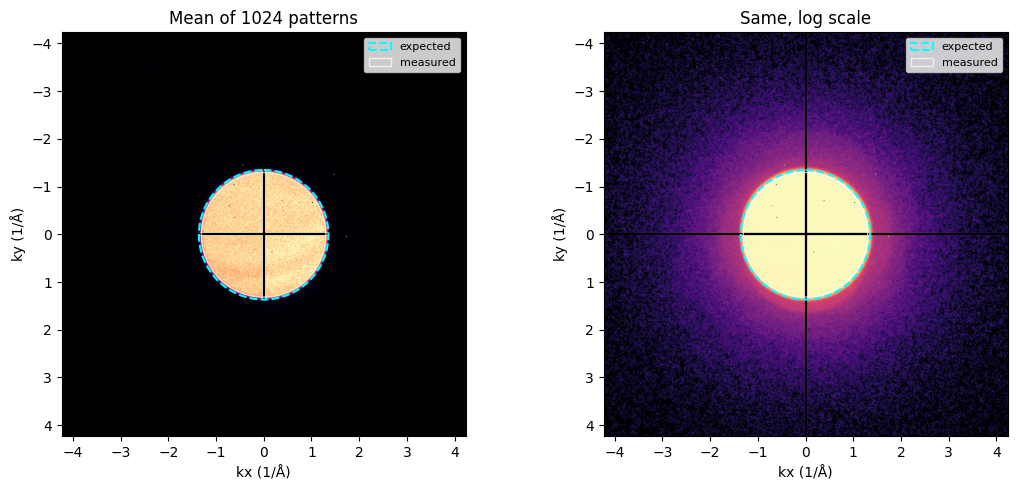

Bright-field disk: measured radius 79.3 px, expected 82.5 px
Disk centre at detector pixel (257.6, 256.9); detector centre is (257.0, 257.0)
OK: calibration and convergence angle are consistent.


In [7]:
CHECK_SCAN = 0            # ✏️ which scan to check: its number in the list above, or its folder name

job = JOBS[CHECK_SCAN] if isinstance(CHECK_SCAN, int) else next(j for j in JOBS if j["name"] == CHECK_SCAN)
assert job["p"] is not None, f"{job['name']} can't be read: {job['error']}"
p = job["p"]
print(f"Scan {job['name']}:  {job['h5']}\n")
describe(p)

cal = check_calibration(p)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
draw_pattern(ax[0], cal.mean, p, cal, f"Mean of {cal.n} patterns")
draw_pattern(ax[1], np.log10(cal.mean + 1e-3), p, cal, "Same, log scale")
plt.tight_layout(); plt.show()
report_calibration(p, cal)

In [8]:
# Optional: list everything inside the HDF5 file of the scan above (groups, datasets, attributes)
# list_h5(job["h5"])

## Step 4 — Convert all scans

This converts the scans one after another, in the same way as the single-file notebook. Each scan takes a while (it's
read once, written once, and 20 random patterns are re-read to check them), so the whole list can take hours.
Each scan shows a dot per block of rows while it runs, then a line with its time, file size and checks.

* If one scan fails, the error is noted and the next scan carries on.
* Each `.zip` is written as `<name>.zip.partial` and renamed only once it's complete and verified. If the run
  stops part-way, it never leaves a half-written file that looks finished. Re-running this cell (with
  `OVERWRITE = False`) picks up from the first unfinished scan.
* Before each scan, the cell checks for enough free disk space for a file the size of the largest one so far,
  and stops if there isn't.
* Each scan's check image goes to `checks/<name>.png`, and a row is added to `conversion_log.csv`.

In [9]:
LOG_CSV = os.path.join(OUTPUT_DIR or os.getcwd(), "conversion_log.csv")
if OUTPUT_DIR:
    os.makedirs(OUTPUT_DIR, exist_ok=True)

todo = [j for j in JOBS if j["p"] is not None and (OVERWRITE or not os.path.exists(j["zip"]))]
largest = max([os.path.getsize(j["zip"]) for j in JOBS if os.path.exists(j["zip"])], default=0)
print(f"Converting {len(todo)} scans; log: {LOG_CSV}\n")

t_start, n_done = time.time(), 0
for i, job in enumerate(todo, 1):
    p, tmp = job["p"], job["zip"] + ".partial"
    free = shutil.disk_usage(os.path.dirname(job["zip"])).free
    if largest and free < 1.2 * largest:
        print(f"STOPPED: only {free / 1e9:.1f} GB free and the largest file so far is {largest / 1e9:.1f} GB. "
              "Free some space and run this cell again to carry on.")
        break

    print(f"[{i}/{len(todo)}] {job['name']} ", end="", flush=True)
    t0 = time.time()
    row = {"name": job["name"], "input": job["h5"], "output": job["zip"],
           "shape": str((p.Ry, p.Rx, p.Qy, p.Qx)), "disk_expected_px": f"{p.expected_radius_px:.1f}"}
    try:
        cal = check_calibration(p)
        job["cal"] = cal
        row["disk_measured_px"] = f"{cal.r:.1f}"
        stats = convert(p, cal, tmp)
        problems = verify(p, tmp)
        if problems:
            raise RuntimeError("verification failed: " + "; ".join(problems))
        os.replace(tmp, job["zip"])
        size = os.path.getsize(job["zip"])
        largest = max(largest, size)
        row.update(status="converted", size_GB=f"{size / 1e9:.2f}", value_range=f"{stats.vmin}..{stats.vmax}",
                   mean_counts=f"{stats.total.mean():.1f}")
        job.update(status="converted", size=size)
        note = (f" {stats.n_rounded} non-integer values rounded." if stats.n_rounded else "")
        print(f" {fmt_time(time.time() - t0)}, {size / 1e9:.2f} GB, values {stats.vmin}..{stats.vmax}, "
              f"disk {cal.r:.1f}/{p.expected_radius_px:.1f} px {'OK' if cal.ok else 'CHECK'}, verified.{note}")
        try:
            save_check(job, p, cal, stats)
        except Exception as err:
            print(f"    (couldn't save the check image: {err})")
    except Exception as err:
        job.update(status="FAILED", error=f"{type(err).__name__}: {err}")
        row.update(status="FAILED", error=job["error"])
        print(f" FAILED after {fmt_time(time.time() - t0)}: {job['error']}")
    finally:
        if os.path.exists(tmp):          # failed or interrupted: remove the half-written file
            os.remove(tmp)
    row.update(finished=time.strftime("%Y-%m-%d %H:%M:%S"), minutes=f"{(time.time() - t0) / 60:.1f}")
    log_row(LOG_CSV, row)

    n_done += 1
    left = len(todo) - i
    if left:
        print(f"    about {fmt_time((time.time() - t_start) / n_done * left)} left")

print(f"\nFinished in {fmt_time(time.time() - t_start)}.")

Converting 38 scans; log: /dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/Zarr/conversion_log.csv

[1/38] 20260524_112119 ...... 1.1 min, 1.85 GB, values 0..63, disk 79.3/82.5 px OK, verified.
    about 41.8 min left
[2/38] 20260524_112644 ...... 1.1 min, 1.82 GB, values 0..63, disk 79.3/82.5 px OK, verified.
    about 41.0 min left
[3/38] 20260524_113110 ...... 1.1 min, 1.86 GB, values 0..63, disk 79.1/82.5 px OK, verified.
    about 40.0 min left
[4/38] 20260524_113554 ...... 1.1 min, 1.84 GB, values 0..63, disk 78.9/82.5 px OK, verified.
    about 38.7 min left
[5/38] 20260524_114023 ...... 1.1 min, 1.81 GB, values 0..63, disk 78.6/82.5 px OK, verified.
    about 37.5 min left
[6/38] 20260524_114443 ...... 1.2 min, 1.79 GB, values 0..63, disk 78.4/82.5 px OK, verified.
    about 36.6 min left
[7/38] 20260524_114951 ...... 1.1 min, 1.79 GB, values 0..63, disk 78.2/82.5 px OK, verified.
    about 35.5 min left
[8/38] 20260524_115357 ...... 1.1 min, 1.81 GB, values 0..63, di

## Step 5 — Summary

This shows a table of every scan, with a virtual bright-field image of each converted scan underneath. It also covers
scans converted in earlier runs, and it can be re-run on its own after Steps 1–3. A **CHECK** in the disk column means the
measured bright-field disk differs from the expected one by more than 10%; look at that scan's check image.

scan                  GB   disk measured / expected px   status
20260524_112119     1.85   79.3 / 82.5 OK                converted
20260524_112644     1.82   79.3 / 82.5 OK                converted
20260524_113110     1.86   79.1 / 82.5 OK                converted
20260524_113554     1.84   78.9 / 82.5 OK                converted
20260524_114023     1.81   78.6 / 82.5 OK                converted
20260524_114443     1.79   78.4 / 82.5 OK                converted
20260524_114951     1.79   78.2 / 82.5 OK                converted
20260524_115357     1.81   77.9 / 82.5 OK                converted
20260524_120002     1.76   77.6 / 82.5 OK                converted
20260524_120714     1.77   77.3 / 82.5 OK                converted
20260524_121253     1.76   77.0 / 82.5 OK                converted
20260524_123150     1.75   76.7 / 82.5 OK                converted
20260524_123848     1.72   76.2 / 82.5 OK                converted
20260524_124500     1.68   75.6 / 82.5 OK                converte

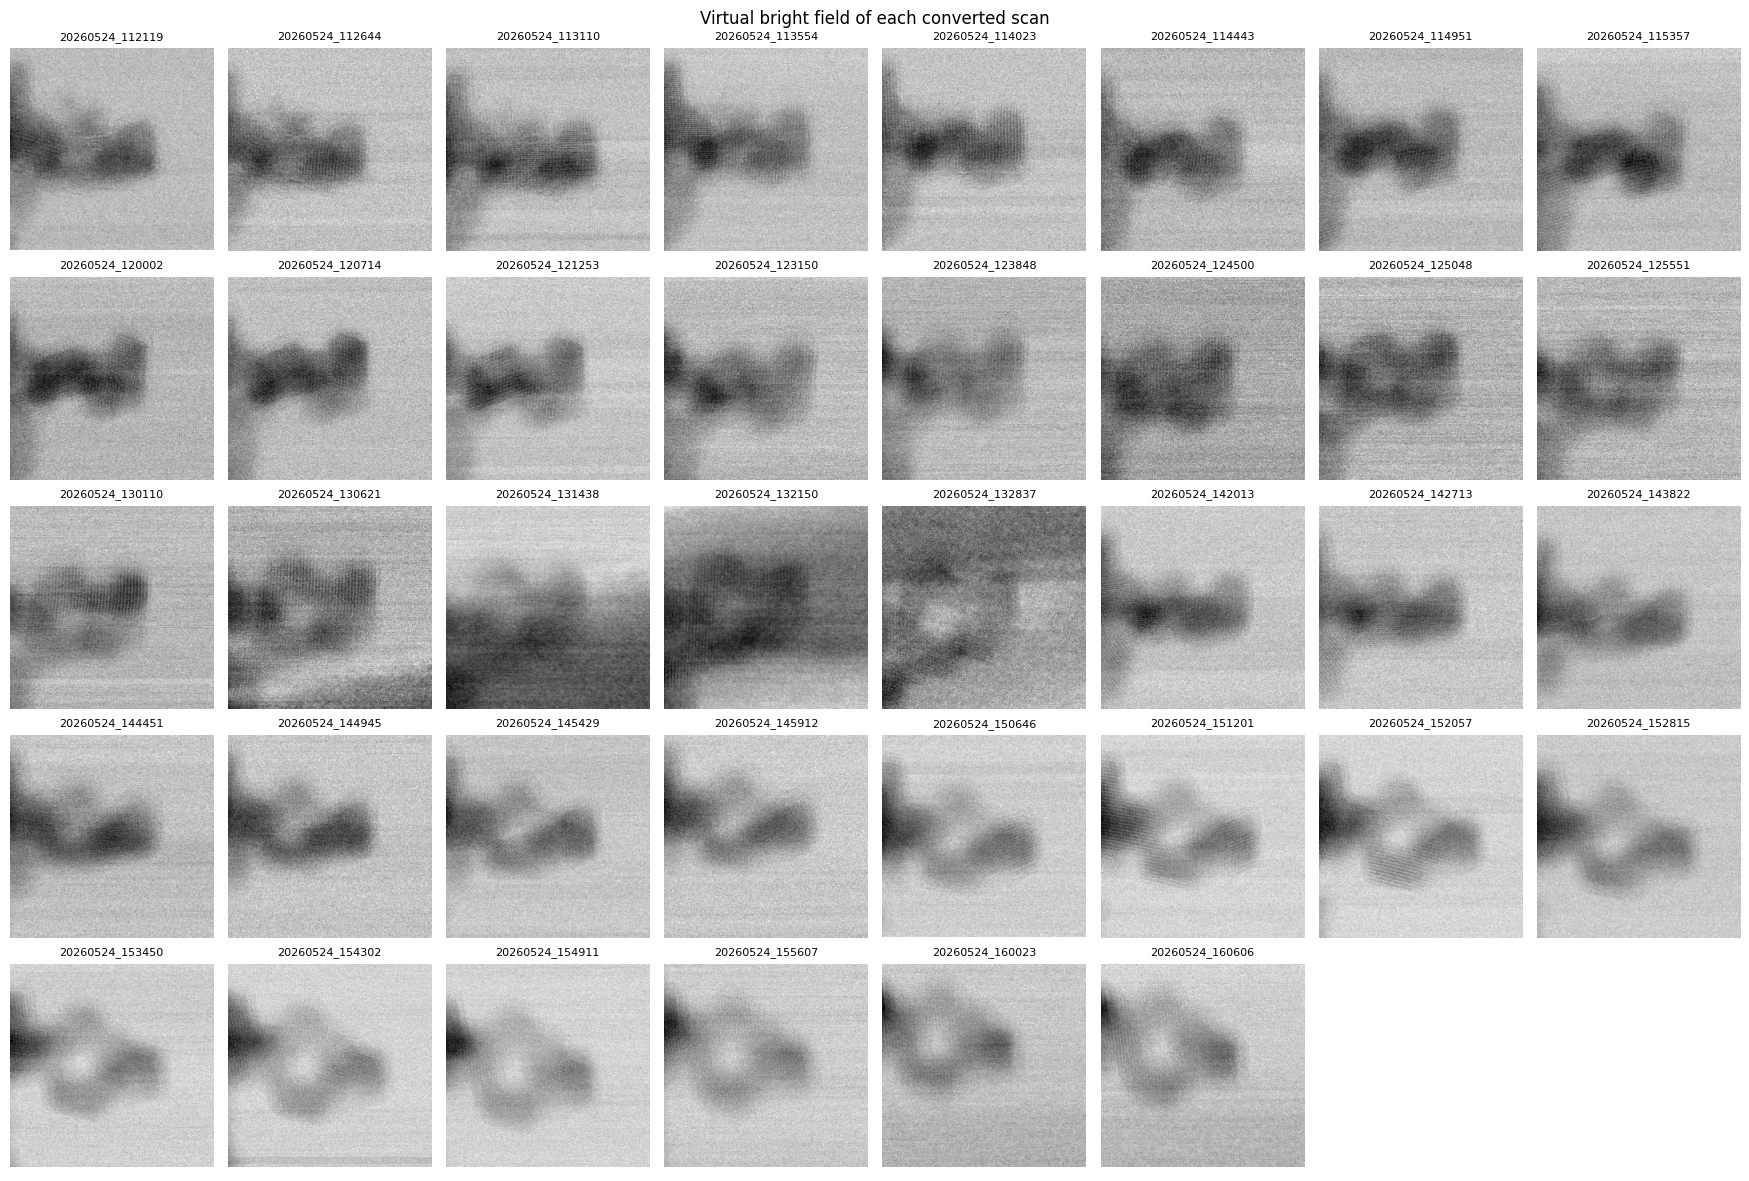

In [10]:
rows, images = [], []
for job in JOBS:
    done = os.path.exists(job["zip"])
    status = job.get("status") or ("converted earlier" if done else
                                   "skipped: " + job["error"] if job["error"] else "not converted")
    size = f"{os.path.getsize(job['zip']) / 1e9:.2f}" if done else "-"
    disk = "-"
    if done and os.path.exists(job["check"] + ".npz"):
        d = np.load(job["check"] + ".npz")
        r, exp = float(d["disk_cy_cx_r"][2]), float(d["expected_radius_px"])
        disk = f"{r:.1f} / {exp:.1f} {'OK' if abs(r - exp) <= 0.1 * exp else 'CHECK'}"
        images.append((job["name"], d["vbf"]))
    if status == "FAILED":
        status += ": " + job["error"]
    rows.append((job["name"], status, size, disk))

print(f"{'scan':<17}{'GB':>7}   {'disk measured / expected px':<30}status")
for name, status, size, disk in rows:
    print(f"{name:<17}{size:>7}   {disk:<30}{status[:110]}")
n_ok = sum(os.path.exists(j["zip"]) for j in JOBS)
total_gb = sum(os.path.getsize(j["zip"]) for j in JOBS if os.path.exists(j["zip"])) / 1e9
print(f"\n{n_ok} of {len(JOBS)} scans converted, {total_gb:.1f} GB in total.")

if images:
    ncol = min(8, len(images))
    nrow = int(np.ceil(len(images) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.2 * ncol, 2.4 * nrow), squeeze=False)
    for a in axes.flat:
        a.axis("off")
    for a, (name, img) in zip(axes.flat, images):
        a.imshow(img, cmap="gray")
        a.set_title(name, fontsize=8)
    fig.suptitle("Virtual bright field of each converted scan")
    plt.tight_layout(); plt.show()

## Step 6 — Compare with a reference dataset (optional) ✏️

This step is copied unchanged from the single-file notebook. It checks one converted file against a known-good file
(e.g. another dataset from the same project), item by item. Every scan is written the same way, so checking one
file is enough. By default that is the first converted scan; set `NEW_ZIP` to check a different one.

Each row is marked:

* **✓ same**
* **~ differs (expected)**: things that naturally differ between datasets (scan size, detector size,
  chunk size, the actual settings values, count levels)
* **✗ DIFFERENT**: a format detail that should match the reference; look at these

The last rows check that the file is consistent with itself (wavelength vs. voltage, and the bright-field
disk size vs. the convergence angle and detector calibration). This last check uses the original disk
measurement, so a hot pixel can still make it fail here.

In [11]:
REFERENCE_ZIP = "/dls/science/groups/e02/Joshua/End_to_End_data/Data/210.zip"   # known-good file
NEW_ZIP = next((j["zip"] for j in JOBS if os.path.exists(j["zip"])), None)      # file to check (first converted scan)
print("Checking", NEW_ZIP)

Checking /dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/Zarr/20260524_112119.zip


In [12]:
import zipfile

CONTROL_FILES = (".zgroup", ".zarray", ".zattrs")


def describe_zip(path):
    # Collect zip layout, Zarr settings, the metadata record and a small data sample
    with zipfile.ZipFile(path) as z:
        infos = z.infolist()
        names = [i.filename for i in infos]
        groups = [n for n in names if n.endswith(".zgroup")]
        prefix = min(groups, key=len)[:-len(".zgroup")] if groups else ""
        control = {n[len(prefix):]: json.loads(z.read(n)) for n in names
                   if n.startswith(prefix) and n.split("/")[-1] in CONTROL_FILES}
    d = {"prefix": prefix or "(none)",
         "stored": all(i.compress_type == zipfile.ZIP_STORED for i in infos),
         "control": control, "meta": None, "data": None}
    store = zarr.ZipStore(path, mode="r")
    try:
        g = zarr.open_group(store, mode="r", path=prefix.rstrip("/"))
        if "meta" in g:
            d["meta"] = g["meta"][0]
        if "data" in g:
            a = g["data"]
            c0, c1 = a.chunks[0], a.chunks[1]
            s = max(1, c0 // 8)
            samp = np.asarray(a[0:c0:s, 0:c1:s]).astype(np.int64)  # sample from the first chunk only
            per = samp.reshape(-1, *samp.shape[2:])
            d["data"] = {"shape": a.shape, "dtype": str(a.dtype), "chunks": a.chunks,
                         "min": int(per.min()), "max": int(per.max()),
                         "counts": float(per.sum(axis=(1, 2)).mean()),
                         "zeros": float((per == 0).mean()), "mean_dp": per.mean(axis=0)}
    finally:
        store.close()
    return d


def self_checks(d):
    # Consistency of a file with itself: wavelength vs voltage, disk size vs alpha + calibration
    m, a = d["meta"], d["data"]
    out = {}
    try:
        h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
        V = m["E_ev"]
        lam = h / np.sqrt(2 * m0 * e * V * (1 + e * V / (2 * m0 * c**2))) * 1e10
        out["wavelength"] = (f"{m['wavelength']:.6f} vs {lam:.6f} Å",
                             abs(m["wavelength"] - lam) / lam < 1e-4)
    except Exception as e:
        out["wavelength"] = (f"can't check ({e})", False)
    try:
        Q = a["shape"][2:]
        dk = np.sqrt((2 * m["k_max"][0] / Q[0]) * (2 * m["k_max"][1] / Q[1]))
        expect = m["alpha_rad"] / m["wavelength"] / dk
        mdp = a["mean_dp"]
        meas = np.sqrt((mdp > 0.5 * mdp.max()).sum() / np.pi)
        out["disk"] = (f"{meas:.1f} measured / {expect:.1f} expected px", abs(meas - expect) < 0.1 * expect)
    except Exception as e:
        out["disk"] = (f"can't check ({e})", False)
    return out


def compare(ref_path, new_path):
    ref, new = describe_zip(ref_path), describe_zip(new_path)
    rows = []

    def add(item, r, n, kind="must"):
        if r == n:
            status = "✓ same"
        else:
            status = "~ differs (expected)" if kind == "info" else "✗ DIFFERENT"
        rows.append((item, r, n, status))

    add("zip: top-level folder", ref["prefix"], new["prefix"])
    add("zip: entries stored uncompressed", ref["stored"], new["stored"])
    add("Zarr control files", sorted(ref["control"]), sorted(new["control"]))
    add(".zgroup", ref["control"].get(".zgroup"), new["control"].get(".zgroup"))

    for arr in ("data", "meta"):
        rz, nz = ref["control"].get(f"{arr}/.zarray", {}), new["control"].get(f"{arr}/.zarray", {})
        for k in sorted(set(rz) | set(nz)):
            kind = "info" if (arr == "data" and k in ("shape", "chunks")) else "must"
            add(f"{arr}/.zarray: {k}", rz.get(k, "(missing)"), nz.get(k, "(missing)"), kind)
        if arr == "data" and rz and nz:
            add("data: number of dimensions", len(rz["shape"]), len(nz["shape"]))
            add("data: whole patterns in each chunk",
                rz["chunks"][2:] == rz["shape"][2:], nz["chunks"][2:] == nz["shape"][2:])

    rm, nm = ref["meta"] or {}, new["meta"] or {}
    add("meta: field names", sorted(rm), sorted(nm))
    shape_of = lambda v: (type(v).__name__, len(v)) if isinstance(v, (list, tuple)) else type(v).__name__
    for k in sorted(set(rm) | set(nm)):
        add(f"meta.{k}: type/length", shape_of(rm[k]) if k in rm else "(missing)",
            shape_of(nm[k]) if k in nm else "(missing)")
        add(f"meta.{k}: value", rm.get(k, "(missing)"), nm.get(k, "(missing)"), "info")

    if ref["data"] and new["data"]:
        rd, nd = ref["data"], new["data"]
        add("sample: value range", f"{rd['min']}..{rd['max']}", f"{nd['min']}..{nd['max']}", "info")
        add("sample: mean counts per pattern", round(rd["counts"], 1), round(nd["counts"], 1), "info")
        add("sample: fraction of zero pixels", round(rd["zeros"], 3), round(nd["zeros"], 3), "info")
        rc, nc = self_checks(ref), self_checks(new)
        for k, label in (("wavelength", "check: wavelength vs E_ev"),
                         ("disk", "check: BF disk vs alpha & k_max")):
            ok_r, ok_n = rc[k][1], nc[k][1]
            status = "✓ consistent" if ok_n else "✗ CHECK (your file)"
            if not ok_r:
                status += " / reference also fails"
            rows.append((label, rc[k][0], nc[k][0], status))

    def cell(v, w):
        s = v if isinstance(v, str) else json.dumps(v) if isinstance(v, (dict, list)) else str(v)
        return s if len(s) <= w else s[:w - 1] + "…"

    W = (36, 40, 40, 22)
    print(f"Reference: {ref_path}\nYours:     {new_path}\n")
    print("  ".join(h.ljust(w) for h, w in zip(("item", "reference", "yours", "result"), W)))
    print("-" * (sum(W) + 6))
    for row in rows:
        print("  ".join(cell(v, w).ljust(w) for v, w in zip(row, W)))

    bad = [r for r in rows if r[3].startswith("✗")]
    print()
    if bad:
        print(f"{len(bad)} item(s) need a look:")
        for r in bad:
            print(f"  - {r[0]}: reference {cell(r[1], 70)} | yours {cell(r[2], 70)}")
    else:
        print("Structure matches the reference: same layout, array settings and metadata fields. "
              "Only dataset-specific values differ.")
    return rows


rows = compare(REFERENCE_ZIP, NEW_ZIP)

Reference: /dls/science/groups/e02/Joshua/End_to_End_data/Data/210.zip
Yours:     /dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/Zarr/20260524_112119.zip

item                                  reference                                 yours                                     result                
------------------------------------------------------------------------------------------------------------------------------------------------
zip: top-level folder                 (none)                                    (none)                                    ✓ same                
zip: entries stored uncompressed      True                                      True                                      ✓ same                
Zarr control files                    [".zgroup", "data/.zarray", "meta/.zarr…  [".zgroup", "data/.zarray", "meta/.zarr…  ✓ same                
.zgroup                               {"zarr_format": 2}                        {"zarr_format": 2}          